# 02 — Exploratory Data Analysis & Business Analytics
**Objective:** quantify booking performance, compare customer/booking segments, and investigate the financial fields without overstating what they measure.

**Important:** booking value, selling price, cost price, markup, refunds, cashback, and coupons are separate fields. This notebook reports them separately and avoids calling a proxy "net profit" or "recognized revenue" without accounting definitions.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
DATA_PATH = Path("../data/hotel_bookings_cleaned.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/Hotels_Booking_Data.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["booking_date", "check_in_date", "check_out_date", "travel_date"])
df["booking_status"] = df["booking_status"].astype(str).str.title()
df["coupon_used"] = df["coupon_used"].astype(str).str.title()
OUT = Path("../visuals")
OUT.mkdir(exist_ok=True)

## 1. Business KPI overview
Cancellation, confirmation, and failure rates use all booking records as the denominator. Counts are record counts because there is no unique booking ID in the source data.

In [2]:
total_bookings = len(df)
status_counts = df["booking_status"].value_counts()
kpis = pd.DataFrame({
    "Metric": ["Total booking records", "Confirmed records", "Cancelled records", "Failed records",
               "Cancellation rate (%)", "Confirmation rate (%)", "Failure rate (%)"],
    "Value": [total_bookings,
              status_counts.get("Confirmed", 0),
              status_counts.get("Cancelled", 0),
              status_counts.get("Failed", 0),
              df["booking_status"].eq("Cancelled").mean()*100,
              df["booking_status"].eq("Confirmed").mean()*100,
              df["booking_status"].eq("Failed").mean()*100]
})
display(kpis.round(2))

,Metric,Value
0,Total booking records,30000.00
1,Confirmed records,21963.00
2,Cancelled records,5779.00
3,Failed records,2258.00
4,Cancellation rate (%),19.26
5,Confirmation rate (%),73.21
6,Failure rate (%),7.53


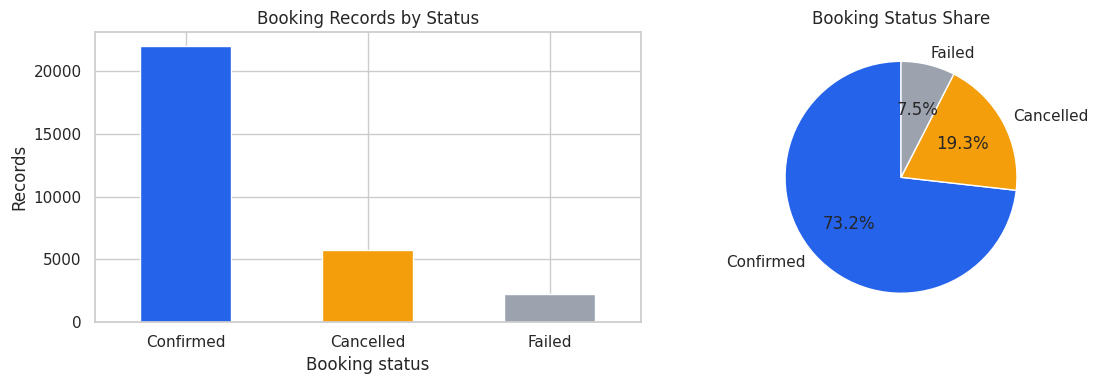

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
status_counts.plot(kind="bar", ax=axes[0], color=["#2563EB", "#F59E0B", "#9CA3AF"])
axes[0].set_title("Booking Records by Status")
axes[0].set_xlabel("Booking status")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=0)
(status_counts / len(df) * 100).plot(kind="pie", ax=axes[1], autopct="%1.1f%%",
                                     startangle=90, ylabel="", colors=["#2563EB", "#F59E0B", "#9CA3AF"])
axes[1].set_title("Booking Status Share")
plt.tight_layout()
plt.savefig(OUT / "booking_status_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Channel performance
`channel_of_booking` and `booking_channel` are different source fields. They are analyzed separately rather than merged.

In [4]:
def cancellation_summary(data, group_column):
    summary = data.groupby(group_column).agg(
        booking_records=("booking_status", "size"),
        cancelled_records=("booking_status", lambda x: x.eq("Cancelled").sum()),
        confirmed_records=("booking_status", lambda x: x.eq("Confirmed").sum()),
        average_booking_value=("booking_value", "mean")
    )
    summary["cancellation_rate_pct"] = summary["cancelled_records"] / summary["booking_records"] * 100
    return summary.sort_values("booking_records", ascending=False)

display(cancellation_summary(df, "channel_of_booking").round(2))
display(cancellation_summary(df, "booking_channel").round(2))

,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
channel_of_booking,,,,,
Web,16023,3031,11776,24973.02,18.92
Android,9505,1845,6931,25355.24,19.41
iOS,4472,903,3256,24881.83,20.19


,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
booking_channel,,,,,
Web,15001,2300,11928,28190.84,15.33
Mobile App,12009,2693,8007,21351.29,22.42
Travel Agent,2990,786,2028,24453.97,26.29


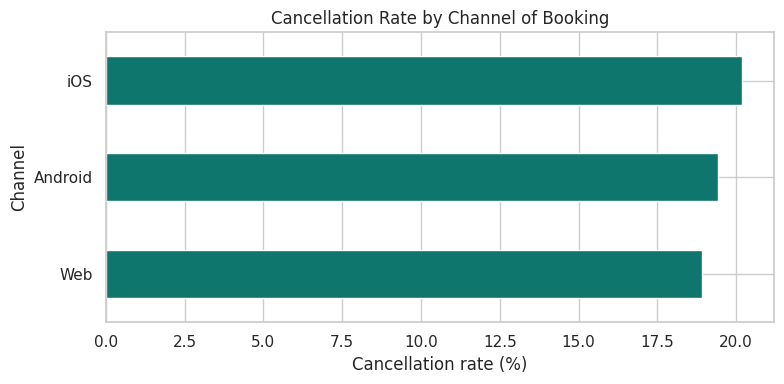

In [5]:
channel_table = cancellation_summary(df, "channel_of_booking").sort_values("cancellation_rate_pct")
ax = channel_table["cancellation_rate_pct"].plot(kind="barh", figsize=(8, 4), color="#0F766E")
ax.set_title("Cancellation Rate by Channel of Booking")
ax.set_xlabel("Cancellation rate (%)")
ax.set_ylabel("Channel")
plt.tight_layout()
plt.savefig(OUT / "cancellation_rate_by_channel.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Room type, star rating, and stay type
These are descriptive comparisons. Differences do not establish that room type or hotel rating causes cancellations.

In [6]:
for col in ["room_type", "star_rating", "stay_type"]:
    print(f"\\nCancellation summary by {col}")
    display(cancellation_summary(df, col).round(2))

\nCancellation summary by room_type


,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
room_type,,,,,
Standard,16552,3662,11647,25146.97,22.12
Deluxe,10478,1645,8030,25004.57,15.70
Suite,2970,472,2286,24978.21,15.89


\nCancellation summary by star_rating


,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
star_rating,,,,,
4,12034,2183,8901,25010.62,18.14
3,10460,2136,7576,25209.57,20.42
5,4511,862,3310,25116.97,19.11
2,2995,598,2176,24855.82,19.97


\nCancellation summary by stay_type


,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
stay_type,,,,,
Leisure,18110,3705,13006,25038.58,20.46
Business,11890,2074,8957,25144.42,17.44


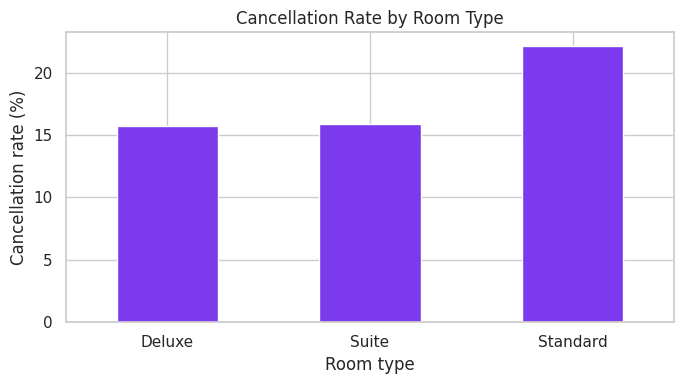

In [7]:
room_rates = cancellation_summary(df, "room_type")["cancellation_rate_pct"].sort_values()
ax = room_rates.plot(kind="bar", figsize=(7, 4), color="#7C3AED")
ax.set_title("Cancellation Rate by Room Type")
ax.set_ylabel("Cancellation rate (%)")
ax.set_xlabel("Room type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "cancellation_by_room_type.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. City-wise performance
City-level comparisons include record volume, cancellation rate, and average listed booking/selling values. They should be interpreted alongside sample sizes.

In [8]:
city_summary = df.groupby("city").agg(
    booking_records=("booking_status", "size"),
    cancelled_records=("booking_status", lambda x: x.eq("Cancelled").sum()),
    average_booking_value=("booking_value", "mean"),
    average_selling_price=("selling_price", "mean"),
    total_selling_price=("selling_price", "sum"),
    average_markup=("markup", "mean")
)
city_summary["cancellation_rate_pct"] = city_summary["cancelled_records"] / city_summary["booking_records"] * 100
display(city_summary.sort_values("booking_records", ascending=False).round(2))

,booking_records,cancelled_records,average_booking_value,average_selling_price,total_selling_price,average_markup,cancellation_rate_pct
city,,,,,,,
Chicago,3059,593,25076.18,29919.36,91523337.40,7190.62,19.39
Los Angeles,3040,612,25365.75,30007.53,91222898.00,7212.77,20.13
Las Vegas,3035,576,24666.21,29665.75,90035550.55,7308.11,18.98
San Francisco,3032,573,25414.25,29864.74,90549893.20,7166.13,18.90
Orlando,3015,588,24900.82,29726.56,89625582.21,7300.30,19.50
New York,2993,589,25033.54,29781.81,89136957.30,7167.63,19.68
Boston,2992,583,25224.13,29692.94,88841285.70,7138.45,19.49
Miami,2959,572,24883.60,29725.64,87958174.93,7302.99,19.33
Seattle,2940,544,25017.52,29623.11,87091936.60,7129.19,18.50


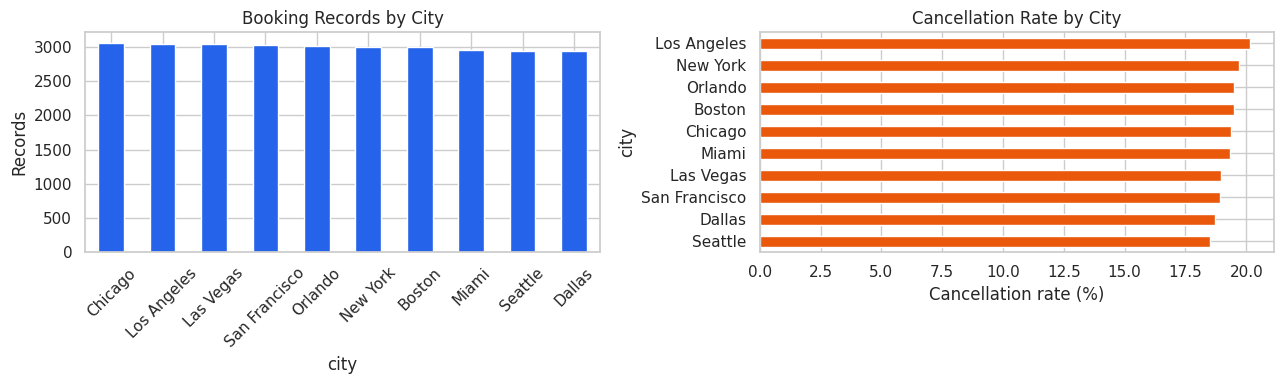

In [9]:
top_cities = city_summary.sort_values("booking_records", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top_cities["booking_records"].plot(kind="bar", ax=axes[0], color="#2563EB")
axes[0].set_title("Booking Records by City")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=45)
top_cities.sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot(kind="barh", ax=axes[1], color="#EA580C")
axes[1].set_title("Cancellation Rate by City")
axes[1].set_xlabel("Cancellation rate (%)")
plt.tight_layout()
plt.savefig(OUT / "city_performance.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Revenue and financial-field analysis
The dataset does not define the accounting treatment of each financial column. The following are therefore reported as recorded amounts, not automatically as recognized revenue or net profit.

The source data satisfies `selling_price ≈ costprice + markup` to floating-point precision. `booking_value` is not identical to `costprice`. Confirm the business definitions with the data owner before using these fields for accounting decisions.

In [10]:
financial_summary = pd.DataFrame({
    "Recorded measure": ["booking_value", "costprice", "markup", "selling_price",
                         "refund_amount", "cashback", "coupon_redeem"],
    "Total recorded amount": [df[c].sum() for c in ["booking_value", "costprice", "markup",
                                                    "selling_price", "refund_amount",
                                                    "cashback", "coupon_redeem"]],
    "Average per booking record": [df[c].mean() for c in ["booking_value", "costprice", "markup",
                                                          "selling_price", "refund_amount",
                                                          "cashback", "coupon_redeem"]]
})
display(financial_summary.round(2))
print("Maximum absolute difference: selling_price - (costprice + markup) =",
      (df["selling_price"] - df["costprice"] - df["markup"]).abs().max())

,Recorded measure,Total recorded amount,Average per booking record
0,booking_value,7.524158e+08,25080.53
1,costprice,6.762448e+08,22541.49
2,markup,2.159925e+08,7199.75
3,selling_price,8.922373e+08,29741.24
4,refund_amount,1.448523e+07,482.84
5,cashback,1.084505e+05,3.62
6,coupon_redeem,1.240491e+05,4.13


Maximum absolute difference: selling_price - (costprice + markup) = 3.637978807091713e-12


In [11]:
status_financial = df.groupby("booking_status").agg(
    records=("booking_status", "size"),
    total_booking_value=("booking_value", "sum"),
    total_selling_price=("selling_price", "sum"),
    total_costprice=("costprice", "sum"),
    total_markup=("markup", "sum"),
    total_refund_amount=("refund_amount", "sum"),
    total_cashback=("cashback", "sum"),
    total_coupon_redeem=("coupon_redeem", "sum")
)
display(status_financial.round(2))

,records,total_booking_value,total_selling_price,total_costprice,total_markup,total_refund_amount,total_cashback,total_coupon_redeem
booking_status,,,,,,,,
Cancelled,5779,1.384352e+08,1.716043e+08,130775901,4.082839e+07,6853459.75,22258.09,26282.41
Confirmed,21963,5.592031e+08,6.534798e+08,494486600,1.589932e+08,6923170.88,77853.70,87924.64
Failed,2258,5.477741e+07,6.715323e+07,50982322,1.617091e+07,708603.48,8338.74,9842.10


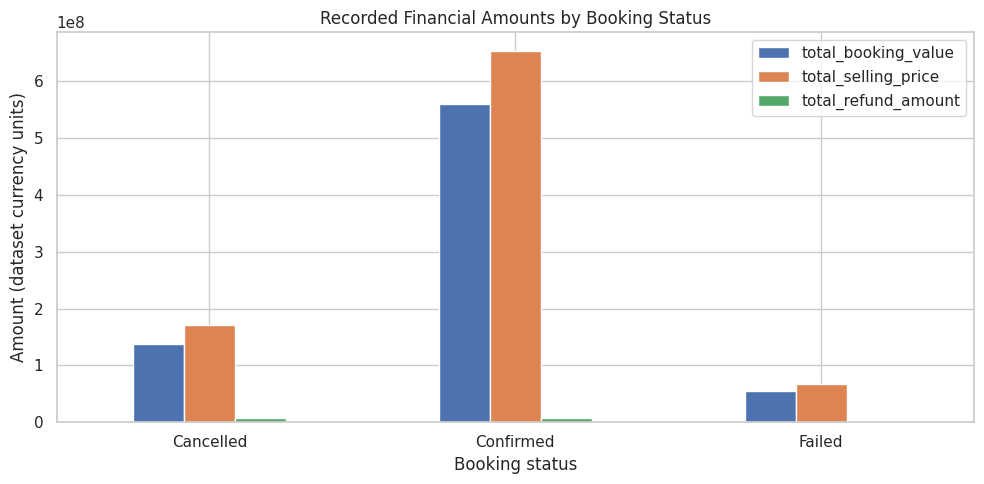

In [12]:
# These values are descriptive recorded totals. They are not net revenue/profit.
ax = status_financial[["total_booking_value", "total_selling_price", "total_refund_amount"]].plot(
    kind="bar", figsize=(10, 5))
ax.set_title("Recorded Financial Amounts by Booking Status")
ax.set_ylabel("Amount (dataset currency units)")
ax.set_xlabel("Booking status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "financial_amounts_by_status.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Coupon, cashback, and payment behaviour
Compare cancellation rates across coupon usage and payment method. These are associations and can be affected by other variables.

In [13]:
display(cancellation_summary(df, "coupon_used").round(2))
display(cancellation_summary(df, "payment_method").round(2))
cashback_summary = df.assign(cashback_used=df["cashback"].gt(0)).groupby("cashback_used").agg(
    booking_records=("booking_status", "size"),
    cancellation_rate_pct=("booking_status", lambda x: x.eq("Cancelled").mean()*100),
    average_booking_value=("booking_value", "mean")
)
display(cashback_summary.round(2))

,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
coupon_used,,,,,
No,23807,4476,17573,25167.90,18.80
Yes,6193,1303,4390,24744.65,21.04


,booking_records,cancelled_records,confirmed_records,average_booking_value,cancellation_rate_pct
payment_method,,,,,
Debit Card,7603,1451,5585,25083.13,19.08
PayPal,7584,1502,5521,25069.86,19.80
Credit Card,7492,1476,5446,24954.58,19.70
Bank Transfer,7321,1350,5411,25217.76,18.44


,booking_records,cancellation_rate_pct,average_booking_value
cashback_used,,,
False,14601,19.04,25034.81
True,15399,19.48,25123.87


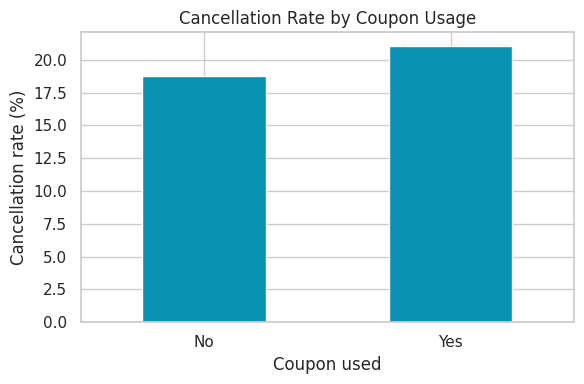

In [14]:
coupon_rate = df.groupby("coupon_used")["booking_status"].apply(lambda x: x.eq("Cancelled").mean()*100)
ax = coupon_rate.plot(kind="bar", figsize=(6, 4), color="#0891B2")
ax.set_title("Cancellation Rate by Coupon Usage")
ax.set_ylabel("Cancellation rate (%)")
ax.set_xlabel("Coupon used")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "cancellation_by_coupon.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Customer and stay behaviour
Customer IDs repeat, but the dataset does not explain whether each ID represents a person, household, or account. Repeat-record counts are therefore treated as repeat customer-ID activity, not verified loyalty.

In [15]:
customer_frequency = df.groupby("customer_id").size()
print("Unique customer IDs:", df["customer_id"].nunique())
print("Customer IDs with more than one record:", (customer_frequency > 1).sum())
print("Share of records belonging to IDs with multiple records (%):",
      df["customer_id"].map(customer_frequency).gt(1).mean()*100)
display(df.groupby("stay_type").agg(
    booking_records=("booking_status", "size"),
    cancellation_rate_pct=("booking_status", lambda x: x.eq("Cancelled").mean()*100),
    average_booking_value=("booking_value", "mean")
).round(2))

Unique customer IDs: 499
Customer IDs with more than one record: 499
Share of records belonging to IDs with multiple records (%): 100.0


,booking_records,cancellation_rate_pct,average_booking_value
stay_type,,,
Business,11890,17.44,25144.42
Leisure,18110,20.46,25038.58


In [16]:
valid_stays = df[df["length_of_stay"].notna() & df["length_of_stay"].gt(0)].copy()
print("Records with a recorded length of stay:", len(valid_stays))
display(valid_stays.groupby("booking_status")["length_of_stay"].agg(["count", "mean", "median"]).round(2))

Records with a recorded length of stay: 24532


,count,mean,median
booking_status,,,
Cancelled,1067,4.00,4.0
Confirmed,21630,4.00,4.0
Failed,1835,4.07,4.0


## 8. Booking-time trends
The monthly trends below use `booking_date`, so they describe when records were created. They should not be labelled as travel seasonality.

In [17]:
df["booking_month"] = df["booking_date"].dt.to_period("M").astype(str)
monthly = df.groupby("booking_month").agg(
    booking_records=("booking_status", "size"),
    cancellation_rate_pct=("booking_status", lambda x: x.eq("Cancelled").mean()*100),
    average_booking_value=("booking_value", "mean")
)
display(monthly.round(2))

,booking_records,cancellation_rate_pct,average_booking_value
booking_month,,,
2024-04,2285,15.14,22550.85
2024-05,2360,15.97,23197.15
2024-06,2284,15.98,24202.79
2024-07,2361,27.57,25501.59
2024-08,2360,26.36,26064.74
2024-09,2284,16.33,24635.11
2024-10,2360,16.19,24880.62
2024-11,2285,15.10,25753.25
2024-12,2360,24.66,23276.99


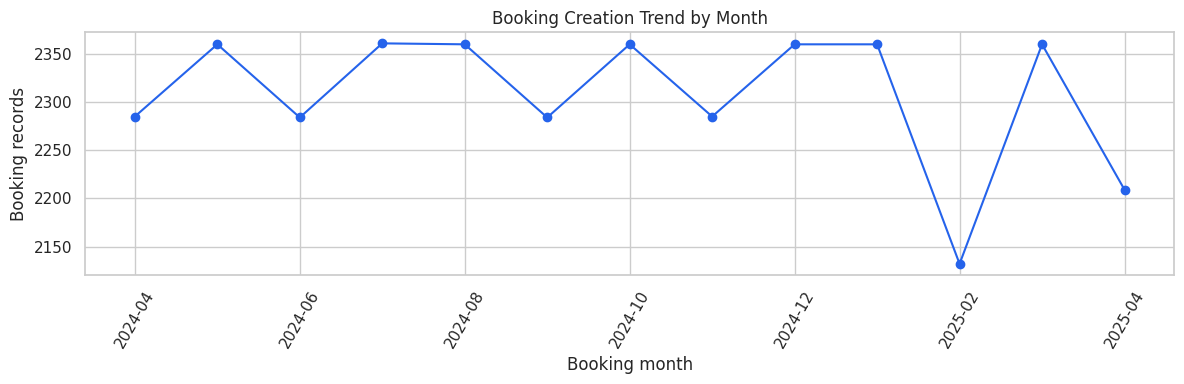

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 4))
monthly["booking_records"].plot(ax=ax1, marker="o", color="#2563EB", label="Booking records")
ax1.set_ylabel("Booking records")
ax1.set_xlabel("Booking month")
ax1.set_title("Booking Creation Trend by Month")
ax1.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(OUT / "monthly_booking_trend.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Lead time and stay-date analysis — valid-date subset only
The check-in date is missing for many cancelled records. Therefore, lead-time analysis is restricted to records with valid booking and check-in dates. It is not representative of all bookings, and no conclusion should be generalized without this caveat.

In [19]:
lead = df.dropna(subset=["booking_date", "check_in_date"]).copy()
lead["lead_time_days"] = (lead["check_in_date"] - lead["booking_date"]).dt.days
lead = lead[lead["lead_time_days"].ge(0)]
lead["lead_time_group"] = pd.cut(
    lead["lead_time_days"],
    bins=[-1, 7, 14, 30, 60, 120, np.inf],
    labels=["0-7", "8-14", "15-30", "31-60", "61-120", "121+"]
)
lead_summary = lead.groupby("lead_time_group", observed=False).agg(
    sample_size=("booking_status", "size"),
    cancellation_rate_pct=("booking_status", lambda x: x.eq("Cancelled").mean()*100)
)
display(lead_summary.round(2))
print("Valid-date subset:", len(lead), "of", len(df), "records")

,sample_size,cancellation_rate_pct
lead_time_group,,
0-7,2921,3.90
8-14,2919,4.56
15-30,6488,4.45
31-60,12204,4.35
61-120,0,NaN
121+,0,NaN


Valid-date subset: 24532 of 30000 records


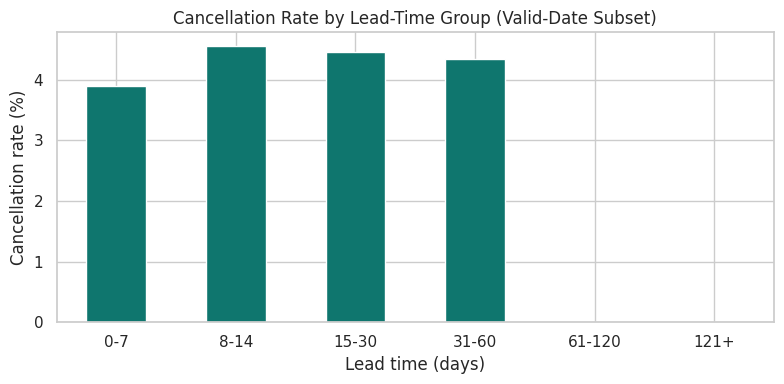

In [20]:
ax = lead_summary["cancellation_rate_pct"].plot(kind="bar", figsize=(8, 4), color="#0F766E")
ax.set_title("Cancellation Rate by Lead-Time Group (Valid-Date Subset)")
ax.set_ylabel("Cancellation rate (%)")
ax.set_xlabel("Lead time (days)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT / "lead_time_cancellation_valid_subset.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Key interpretation and limitations
- Compare cancellation rates with group sizes; a high percentage from a small group may be unstable.
- The strong relationship between missing check-in dates and cancellation status means date-derived analysis is selected on data availability.
- Booking channel, coupon, city, room, and customer patterns are observational associations, not causal effects.
- `selling_price = costprice + markup` is an arithmetic relationship in this file, not proof that markup equals realized profit.
- The dataset's financial definitions and currency are not documented. Avoid calling the totals revenue, profit, or loss without confirmation.

In [21]:
# Export a compact, reusable KPI table.
kpi_export = pd.DataFrame({
    "metric": ["total_records", "confirmed_records", "cancelled_records", "failed_records",
               "cancellation_rate_pct", "confirmation_rate_pct", "failure_rate_pct",
               "missing_checkin_records", "missing_checkin_pct"],
    "value": [len(df), (df.booking_status=="Confirmed").sum(), (df.booking_status=="Cancelled").sum(),
              (df.booking_status=="Failed").sum(), (df.booking_status=="Cancelled").mean()*100,
              (df.booking_status=="Confirmed").mean()*100, (df.booking_status=="Failed").mean()*100,
              df.check_in_date.isna().sum(), df.check_in_date.isna().mean()*100]
})
kpi_export.to_csv("../visuals/business_kpis.csv", index=False)
display(kpi_export.round(2))

,metric,value
0,total_records,30000.00
1,confirmed_records,21963.00
2,cancelled_records,5779.00
3,failed_records,2258.00
4,cancellation_rate_pct,19.26
5,confirmation_rate_pct,73.21
6,failure_rate_pct,7.53
7,missing_checkin_records,5468.00
8,missing_checkin_pct,18.23
